In [3]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv


In [2]:
load_dotenv()

True

In [13]:
llm = ChatGoogleGenerativeAI(
    model='gemini-3.6-flash'
)

In [4]:
#define the state
class llmState(TypedDict):
    topic: str
    outline: str
    content: str

In [6]:
#define the generate_outline node
def generate_outline(state: llmState)->llmState:
    topic=state['topic']

    prompt=f'Generate a outline on the topic: \n {topic}'
    outline=llm.invoke(prompt)

    state['outline']=outline

    return state

In [7]:
#define the generate blog node
def generate_blog(state: llmState)->llmState:
    outline=state['outline']

    prompt=f'Create a blog from the following outline: \n {outline}'

    blog=llm.invoke(prompt)

    state['content']=blog

    return state

In [10]:
#create an instance of graph
graph=StateGraph(llmState)

#define the nodes in the graph
graph.add_node('generate_outline', generate_outline)
graph.add_node('generate_blog', generate_blog)

#create edges to define workflow
graph.add_edge(START, 'generate_outline')
graph.add_edge('generate_outline', 'generate_blog')
graph.add_edge('generate_blog', END)

#compile the graph

workflow=graph.compile()


In [17]:
initial_state={'topic': 'AI Agents'}
final_state=workflow.invoke(initial_state)

answer=final_state['content'].content
print(answer[0]['text'])

# The Rise and Future of AI Agents: From Passive Tools to Autonomous Coworkers

For the past few years, our interaction with Artificial Intelligence has followed a familiar pattern: we type a prompt, and the AI generates a response. We ask ChatGPT for a recipe, request a summary of a PDF, or ask Claude to fix a syntax error in our code. While impressive, this paradigm keeps the human firmly in the driver’s seat. The AI remains a **passive tool**—waiting, reacting, and stopping the moment it finishes generating text.

Now, a fundamental shift is underway. We are moving from passive text generators to **AI Agents**: dynamic, goal-driven entities that can independently perceive their environment, create multi-step plans, execute actions, and adapt when things go wrong.

This isn't just an incremental update to chatbot capabilities; it represents a major paradigm shift in computing. We are moving from **user-driven operations** to **goal-driven execution**.

---

## 1. Fundamentals & Evolu

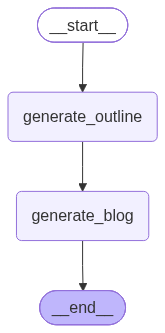

In [18]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())